# Resolve gene dynamics by lineage

A pseudotime places every cell on one axis. When a process branches, that axis pools the
branches: a gene that rises toward one fate is averaged with cells that went another way, and
its trend looks weak. A fate map adds, for each cell, a probability of reaching each candidate
endpoint. Here we use those probabilities as weights, so that each **lineage** counts every
cell by how strongly it connects to that lineage's endpoint, the approach of
[CellRank](https://doi.org/10.1038/s41592-021-01346-6).

We continue the developing-pancreas example of [](fate_mapping.ipynb) with four endocrine
fates, Alpha, Beta, Delta, and Epsilon, and ask three questions:

1. Which genes change along each lineage, and which does a single pseudotime miss?
2. Which genes go with commitment to each fate where the lineages part?
3. How do expression programs differ between the lineages?

## Open the prepared analysis

In [1]:
# Work with numeric arrays and tables.
import numpy as np
import pandas as pd

# Open count stores and run CyteArc analyses.
import cytearc

# Keep routine logs and progress bars out of the results.
cytearc.configure_output(level="WARNING", progress=False)

# Download the prepared example store.
dataset = cytearc.cytebase.connect("cytearc_docs").download_dataset(
    name="bastidas-ponce_4K_pancreas-d15_rnaseq",
    destination="cytearc_datasets",
    zarr=True,
)

# Open the count store for this analysis.
ds = cytearc.DataStore(f"{dataset}/data.zarr", nthreads=4)

# Open the saved RNA analysis of the pancreas cells.
analysis_run = ds.pipeline.open(label="rna")

# Keep the graph and the full feature selection of the saved analysis.
graph = analysis_run["connectivity_map"]
all_features = analysis_run["feature_universe"]

Started: 2026-10-24T12:21:39.928149Z | Wall time: 5.889 s

## Map four candidate fates

As in [](pseudotime.ipynb), the Ductal cells share a total source weight of -1 and the
endocrine populations share +1, which orients the graph. We then freeze the published cell
types as sink labels and map the four endocrine fates, so every Alpha, Beta, Delta, and
Epsilon cell becomes an endpoint of its own lineage.

In [2]:
# Read the published cell types of the scored cells.
annotations = ds.cells.fetch("clusters", key="I")

# Name the four candidate endocrine fates.
fates = ["Alpha", "Beta", "Delta", "Epsilon"]

# Mark the starting population and the pooled endpoints.
source = annotations == "Ductal"
sink = np.isin(annotations, fates)

# Share a total weight of -1 among source cells and +1 among endpoint cells.
source_sink_vector = np.zeros(len(annotations), dtype=float)
source_sink_vector[source] = -1.0 / source.sum()
source_sink_vector[sink] = 1.0 / sink.sum()

# Score pseudotime with the chosen source and endpoints.
pseudotime_ref = ds.trajectory.pseudotime(graph, ss_vec=source_sink_vector)

# Keep the selection of the scored cells.
scored_cells = ds.trajectory.load_pseudotime(pseudotime_ref).cell_selection

# Freeze the published cell types of those cells as sink labels.
cell_types = ds.snapshot_cluster_labels("clusters", cell_selection=scored_cells)

# Map how strongly each cell connects to each fate.
fate_ref = ds.trajectory.fate(pseudotime_ref, cell_types, sinks=fates)

Started: 2026-10-24T12:21:45.818398Z | Wall time: 1.323 s

Summarize the probabilities within each published cell type:

In [3]:
# Load the fate probabilities of the scored cells.
fate = ds.trajectory.load_fate(fate_ref)

# Average each fate's probability within every published cell type.
pd.DataFrame(fate.values, columns=fates).groupby(annotations).mean().round(2)

,Alpha,Beta,Delta,Epsilon
Alpha,1.00,0.00,0.00,0.00
Beta,0.00,1.00,0.00,0.00
Delta,0.00,0.00,1.00,0.00
Ductal,0.23,0.45,0.04,0.29
Epsilon,0.00,0.00,0.00,1.00
Ngn3 high EP,0.23,0.45,0.04,0.29
Ngn3 low EP,0.23,0.45,0.04,0.29
Pre-endocrine,0.29,0.53,0.04,0.14


Started: 2026-10-24T12:21:47.143205Z | Wall time: 0.182 s

Endpoint cells have probability one for their own fate. Earlier cells spread their
probability across the fates and lean toward Beta, the largest endocrine population, while
Delta, the smallest, receives little probability upstream. These probabilities describe this
graph and these endpoints, not the observed future of any cell.

## Follow genes along each lineage

`trajectory.markers` correlates each gene with pseudotime over all scored cells.
`trajectory.lineage_markers` correlates each gene with pseudotime once per lineage, weighting
every cell by its probability of that lineage's fate. Cells of the shared trunk count in every
lineage, and cells drawn to another fate count little.

In [4]:
# Correlate genes with pseudotime once per lineage, weighted by fate probability.
lineage_ref = ds.trajectory.lineage_markers(fate_ref, features=all_features)

# Load the per-lineage correlations.
lineage_markers = ds.trajectory.load_lineage_markers(lineage_ref)

# Show how many equally weighted cells each lineage amounts to.
pd.Series(
    lineage_markers.effective_cells, index=fates, name="effective cells"
).round(0)

Alpha      1769.0
Beta       2579.0
Delta       343.0
Epsilon    1746.0
Name: effective cells, dtype: float64

Started: 2026-10-24T12:21:47.327564Z | Wall time: 2.833 s

Each lineage's p-values use its *effective* number of cells, Kish's
$(\sum w)^2 / \sum w^2$ of its weights $w$. Delta amounts to a few hundred equally weighted
cells and the other lineages to well over a thousand, so its statistics are less certain.
P-values also treat cells as independent: use them to rank genes, not as evidence across
samples.

Compare these correlations with the pooled pseudotime for two known markers of each fate:

In [5]:
# Correlate genes with the pooled pseudotime over all scored cells.
pooled_ref = ds.trajectory.markers(pseudotime_ref, features=all_features)

# Index the pooled correlations by gene name.
pooled = ds.trajectory.load_markers(pooled_ref).table.set_index("feature_name")

# Arrange the per-lineage correlations as genes by lineages.
by_lineage = lineage_markers.table.pivot(
    index="feature_name", columns="lineage", values="r_value"
)

# Choose two known markers of each endocrine fate.
fate_markers = ["Gcg", "Arx", "Ins1", "Pdx1", "Sst", "Hhex", "Ghrl", "Mboat4"]

# Compare the pooled and per-lineage correlations of those genes.
by_lineage.loc[fate_markers].assign(
    pooled=pooled.loc[fate_markers, "r_value"]
).round(2)

lineage,Alpha,Beta,Delta,Epsilon,pooled
feature_name,,,,,
Gcg,0.36,0.06,0.04,0.19,0.22
Arx,0.42,0.20,NaN,0.50,0.33
Ins1,0.08,0.26,0.06,0.10,0.18
Pdx1,0.10,0.56,0.37,0.05,0.37
Sst,0.01,0.08,0.39,0.05,0.09
Hhex,-0.35,-0.23,0.57,-0.25,-0.12
Ghrl,0.08,0.04,0.10,0.49,0.14
Mboat4,0.10,0.07,0.27,0.38,0.14


Started: 2026-10-24T12:21:50.165475Z | Wall time: 1.343 s

The pooled pseudotime barely registers Sst and even ranks Hhex as falling, because most
cells late in pseudotime are Alpha and Beta cells that do not express them. Weighted by the
Delta fate, both rise. Ghrl and Mboat4 behave the same way for Epsilon. A missing value marks
a gene left untested in a lineage, because its expressing cells carry less than 10 cells' worth
of that lineage's weight.

Genes shared by all endocrine cells rise along every lineage, so a lineage's strongest
correlations are often shared ones. To find genes specific to one lineage, compare each
lineage with the others:

In [6]:
# Subtract each gene's mean correlation in the other lineages.
specific = pd.DataFrame(
    {
        lineage: by_lineage[lineage] - by_lineage.drop(columns=lineage).mean(axis=1)
        for lineage in fates
    }
)

# List the five most lineage-specific rising genes of each lineage.
pd.DataFrame({lineage: specific[lineage].nlargest(5).index for lineage in fates})

,Alpha,Beta,Delta,Epsilon
0,Mgst3,Nkx6-1,Cd24a,Mdk
1,Grb10,Ociad2,Hhex,Anpep
2,Gcg,Pdx1,Hadh,Cd63
3,Hspe1,Slc2a2,Igfbp5,Cdkn1a
4,Higd1a,Sytl4,Dlk1,Ghrl


Started: 2026-10-24T12:21:51.510789Z | Wall time: 0.035 s

Each column now names genes that rise toward one fate more than toward the others,
such as Gcg toward Alpha, Pdx1, Nkx6-1, and Slc2a2 toward Beta, Hhex toward Delta, and Ghrl
toward Epsilon. These are candidates to inspect, not evidence that a gene drives its
lineage.

## Find genes that go with commitment

Pseudotime correlations follow genes along a lineage. Lineage **drivers** ask a different
question: among cells that have not committed, which genes rise with the probability of one
fate? `trajectory.drivers` correlates each gene with each fate probability and tests it with
Fisher's z-transform. It leaves out the endpoint cells by default, because their
probabilities are fixed at zero or one and would mostly recover the markers that defined the
endpoints.

The lineages part in the Ngn3-high progenitors and pre-endocrine cells, so we restrict the
search to them.

In [7]:
# Mark the cells where the lineages part.
branch = np.isin(annotations, ["Ngn3 high EP", "Pre-endocrine"])

# Save the mark as a cell column and freeze it as a selection.
ds.cells.insert("branch_cells", branch, key="I", overwrite=True)
branch_cells = ds.snapshot_cell_selection("branch_cells")

# Correlate genes with each fate probability within those cells.
drivers_ref = ds.trajectory.drivers(fate_ref, features=all_features, cells=branch_cells)

# Load the driver table.
drivers = ds.trajectory.load_drivers(drivers_ref)

# Order the drivers of each fate from the strongest correlation down.
ranked = drivers.table.sort_values(["lineage", "r_value"], ascending=[True, False])

# Show the four strongest drivers of each fate with their confidence intervals.
ranked.groupby("lineage").head(4)[
    ["lineage", "feature_name", "r_value", "ci_low", "ci_high"]
].round(3)

,lineage,feature_name,r_value,ci_low,ci_high
20653,Alpha,Usp18,0.400,0.352,0.446
23549,Alpha,Cpe,0.390,0.342,0.437
27246,Alpha,Tmem27,0.388,0.340,0.435
27010,Alpha,Arx,0.371,0.322,0.418
41989,Beta,Chgb,0.459,0.414,0.502
41019,Beta,Mafb,0.439,0.393,0.483
42017,Beta,Pcsk2,0.433,0.386,0.477
28263,Beta,Cryba2,0.398,0.350,0.444
67894,Delta,Hhex,0.683,0.652,0.712
64790,Delta,Sst,0.551,0.511,0.589


Started: 2026-10-24T12:21:51.547952Z | Wall time: 1.379 s

Known regulators appear without being asked for. Hhex, a transcription factor that
delta cells need, leads the Delta drivers with Sst and Pyy; Mafb and the secretory-granule
genes Chgb and Pcsk2 lead Beta; and Arx, a determinant of alpha cells, is among the strongest
Alpha drivers. The Epsilon drivers mix ribosomal genes with Cdkn1a, which marks cells leaving
the cell cycle, a reminder that drivers can follow cell state as much as fate. The intervals
are narrow because hundreds of cells contribute, but all of them come from one graph and one
sample: a driver is a candidate regulator of commitment, not a demonstrated cause.

## Compare expression programs across lineages

`trajectory.lineage_aggregation` summarizes genes along every lineage. Along pseudotime, each
lineage's fate weight is cut into 50 bins of equal weight, so each lineage runs from the shared
start to its endpoint, and neighbouring bins are smoothed together. Each gene is scaled once
across all lineages, which keeps its lineages comparable, and genes with similar profiles
across the lineages form modules. We profile the highly variable genes of the saved analysis;
the full gene set adds thousands of flat or sparse profiles.

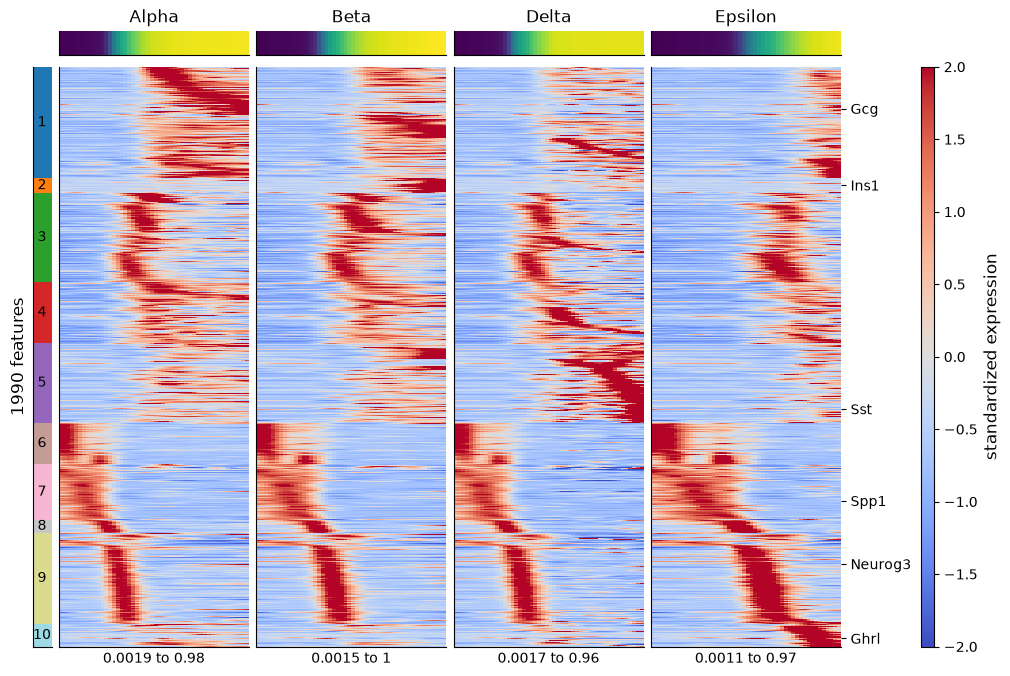

Started: 2026-10-24T12:21:52.929772Z | Wall time: 2.140 s

In [8]:
# Keep the highly variable genes of the saved analysis.
variable_features = analysis_run["highly_variable_features"]

# Bin each gene along every lineage and group the genes into modules.
profiles_ref = ds.trajectory.lineage_aggregation(fate_ref, features=variable_features)

# Display the lineage profiles side by side.
ds.plots.lineage_heatmap(
    aggregation=profiles_ref,
    show_features=["Spp1", "Neurog3", "Gcg", "Ins1", "Sst", "Ghrl"],
)

Read each panel from the shared start on the left to the endpoint on the right.
Modules that fade on every panel are progenitor programs; modules that rise on one panel only
are fate programs. The strip above each panel shows the bins' mean pseudotime: bins near an
endpoint span little pseudotime, because pseudotime levels off inside the endpoints. The
Delta panel is noisier than the others because its lineage carries the least fate weight.

Module numbers are labels, not stages. For individual genes, plot the profiles of every
lineage together. The x-axis is each lineage's progress, the share of its fate weight already
passed, so the endpoints are as wide as the trunk:

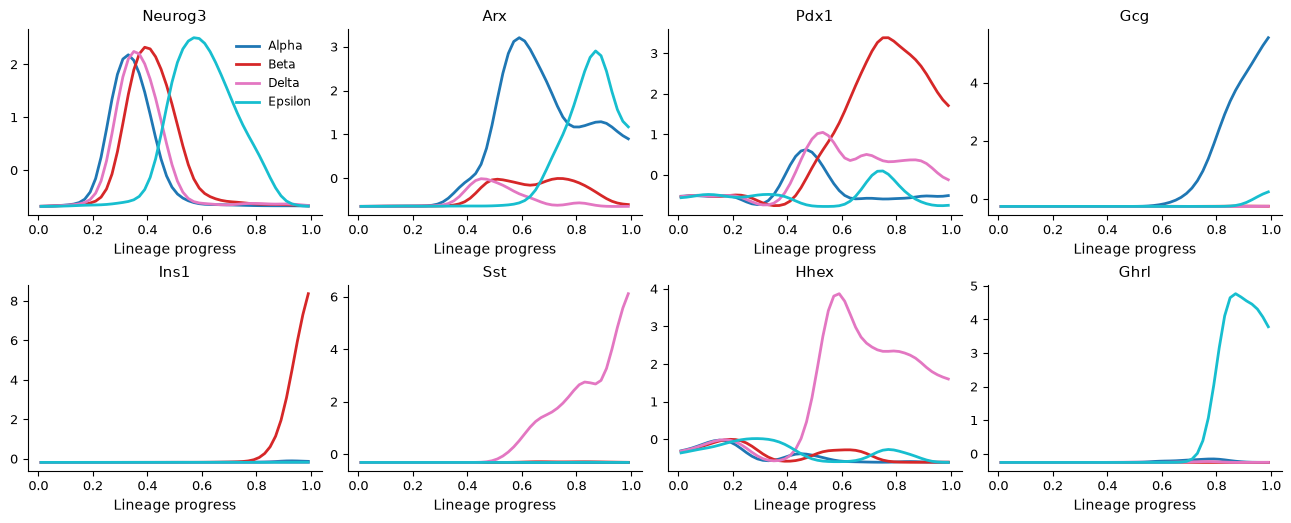

Started: 2026-10-24T12:21:55.072594Z | Wall time: 0.965 s

In [9]:
# Plot a few genes' profiles along every lineage.
ds.plots.lineage_trends(
    aggregation=profiles_ref,
    features=["Neurog3", "Arx", "Pdx1", "Gcg", "Ins1", "Sst", "Hhex", "Ghrl"],
    n_columns=4,
)

Neurog3 peaks in the shared trunk of every lineage before the lineages part, while the
hormone genes rise toward one endpoint each. Arx rises toward Alpha and Epsilon, and Pdx1
toward Beta. The Neurog3 peak sits later on the Epsilon lineage because progress counts fate
weight: the Epsilon endpoint is small, so progenitors carry most of that lineage's weight and
fill more of its axis. Compare the order of events within a lineage, not positions across
lineages. Profiles are scaled per gene across lineages, so the curves show where a gene is
relatively high, not its absolute abundance. Pass `axis="pseudotime"` to plot against
pseudotime instead.

## Common mistakes and limitations

- Reading shared programs as fate-specific: the trunk counts in every lineage, so a lineage's
  strongest correlations include pan-endocrine genes. Compare lineages, as above, or use
  drivers.
- Treating fate probabilities as observed fates: they depend on the graph, the pseudotime, and
  the chosen endpoints, and a missing endpoint redistributes its probability among the others.
  Compare plausible endpoint sets as in [](trajectory_validation.md).
- Including endpoint cells in drivers: their probabilities are fixed by the model, which makes
  their driver scores circular.
- Over-reading p-values: they assume independent cells, and the effective number of cells
  accounts only for unequal weights.

Continue to [](lineage_curves.ipynb) to draw the lineages over a UMAP and to check candidate
endpoints with a cluster tree.